# Supplementary Figure 9 — large-scale virtual screening on the time-dependent test set

Two panels, drawn from `raw_data/`, the Source Data submitted with the paper. Download it
from the Zenodo record linked in the repository README and unpack it at the repository root,
so `raw_data/` sits next to `smartbind/`; the notebook walks up to find it.

| panel | what it draws | source table |
|---|---|---|
| **9a** | SMARTBind vs each of eight baselines, one scatter per baseline, 34 time-dependent targets | `SupplementaryFig9a_pairwise_smartbind_vs_baselines.csv` |
| **9b** | mean rank percentile by data-leakage filter, ten methods | `SupplementaryFig9b_rank_percentile_by_filter_group.csv` |

**Reading panel a.** Both axes are the *inverse* rank percentile, so **lower is better** and a
point **above** the diagonal is a SMARTBind win. The win counts in each inset are recomputed
here from the per-point table rather than typed in.

**One point differs from the published figure.** In the SMARTBind-vs-GerNA-Bind panel the
published inset reads 31/34 and draws a third red point at y ≈ 15. That point is case
**8ZNQ_NAZ**, and y ≈ 15 is its *pre-retraining* GerNA-Bind score of 14.7490. GerNA-Bind was
subsequently retrained, which moved that case to 73.0269, above the diagonal, a SMARTBind
win, giving 32/34. The published panel was drawn from a table that carried the retrained
value everywhere except this one row, so it mixes the two runs; every other point, including
the two red ones (9V4X_9QC and 9IWF_XAN), is retrained. The Source Data ships the retrained
column throughout, and this notebook draws it, so the inset here reads 32/34.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats as sp_stats


def find_raw_data():
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        if (folder / "raw_data").is_dir():
            return folder / "raw_data"
    raise SystemExit(
        "\nCould not find `raw_data/`.\n\n"
        "The raw data is not provided with the release. Reproduce the underlying\n"
        "numbers with the inference scripts.\n")


RAW = find_raw_data() / "SupplementaryFig9"
OUT = Path("figures")
OUT.mkdir(exist_ok=True)

pairwise = pd.read_csv(RAW / "SupplementaryFig9a_pairwise_smartbind_vs_baselines.csv")
pairwise_summary = pd.read_csv(RAW / "SupplementaryFig9a_summary.csv")
by_filter = pd.read_csv(RAW / "SupplementaryFig9b_rank_percentile_by_filter_group.csv")
by_filter_summary = pd.read_csv(RAW / "SupplementaryFig9b_summary.csv")

# Panel order as published: left to right, top row then bottom.
BASELINES = ["RNAmigos1", "RNAmigos2", "RNAsmol", "GerNA-Bind",
             "GNINA1.3", "DeepDocking", "DrugBAN_RNA", "GraphDTA_RNA"]

print(f"{len(pairwise):,} points = {pairwise.baseline_method.nunique()} baselines "
      f"x {pairwise.case.nunique()} targets")
print("\nwin counts recomputed from the per-point table vs the shipped summary:")
for b in BASELINES:
    d = pairwise[pairwise.baseline_method == b]
    wins = int((d.y_baseline_inverse_rank_percentile > d.x_smartbind_inverse_rank_percentile).sum())
    losses = int((d.y_baseline_inverse_rank_percentile < d.x_smartbind_inverse_rank_percentile).sum())
    row = pairwise_summary[pairwise_summary.baseline_method == b].iloc[0]
    ok = wins == row.inset_smartbind_wins and losses == row.inset_baseline_wins
    print(f"  {b:<14} recomputed {wins:>2}/{losses:<2}   shipped {row.inset_smartbind_wins:>2}/"
          f"{row.inset_baseline_wins:<2}   {'ok' if ok else 'MISMATCH'}")

272 points = 8 baselines x 34 targets

win counts recomputed from the per-point table vs the shipped summary:
  RNAmigos1      recomputed 33/1    shipped 33/1    ok
  RNAmigos2      recomputed 32/2    shipped 32/2    ok
  RNAsmol        recomputed 32/2    shipped 32/2    ok
  GerNA-Bind     recomputed 32/2    shipped 32/2    ok
  GNINA1.3       recomputed 33/1    shipped 33/1    ok
  DeepDocking    recomputed 32/2    shipped 32/2    ok
  DrugBAN_RNA    recomputed 34/0    shipped 34/0    ok
  GraphDTA_RNA   recomputed 32/2    shipped 32/2    ok


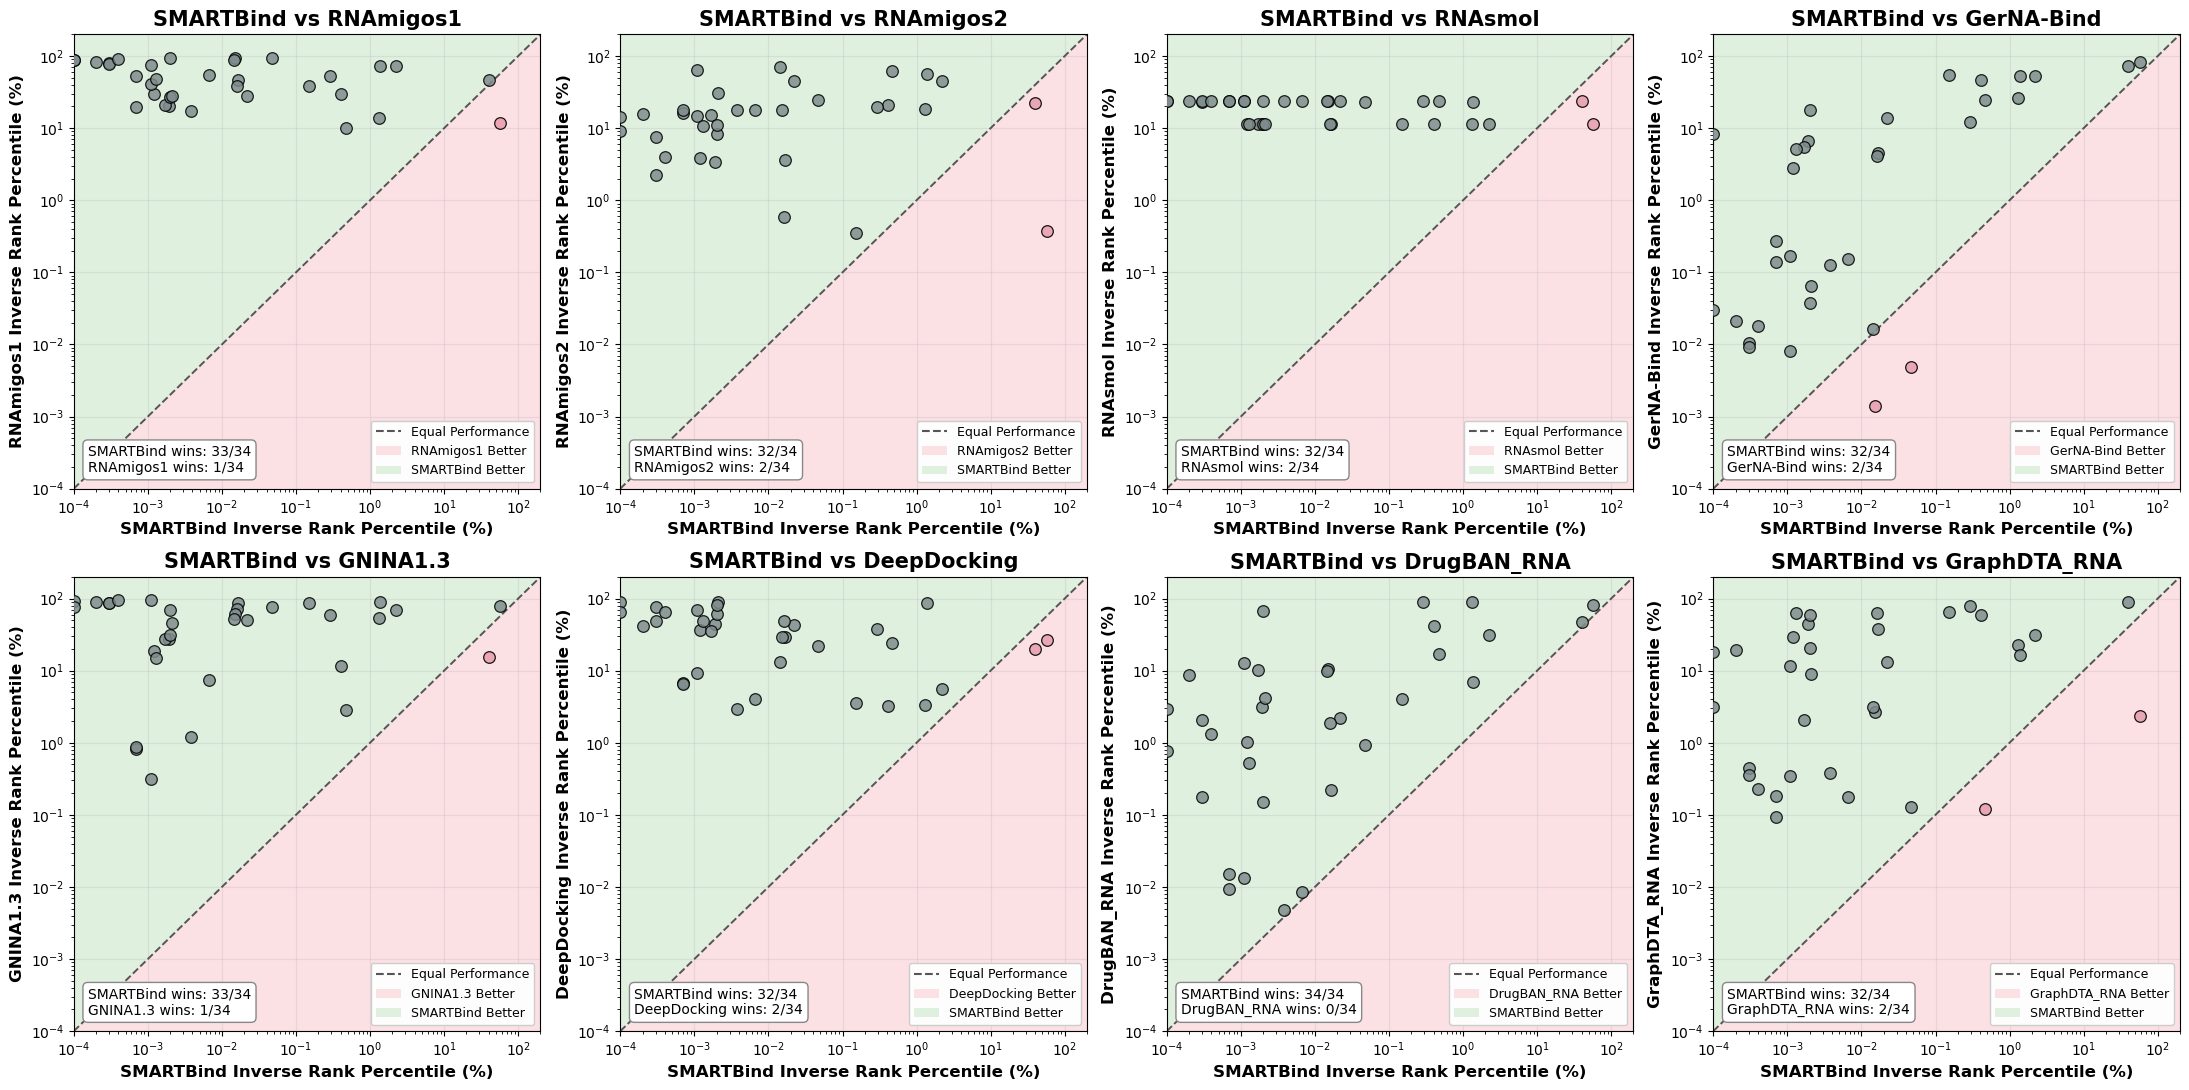

  the case that differs from the published panel: 9FN2_SAH
    SMARTBind x = 56.8668, GerNA-Bind y = 83.9511 -> above the diagonal, winner = SMARTBind


In [2]:
# ── Supplementary Fig. 9a — SMARTBind vs each baseline ──────────────────────
# Both axes are the inverse rank percentile: lower is better, so a point above the
# diagonal is a SMARTBind win. Axes are log-scaled and share the published limits.
LO, HI = 1e-4, 2e2
GREEN, PINK = "#DFF0DF", "#FBE0E4"

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
for ax, baseline in zip(axes.ravel(), BASELINES):
    d = pairwise[pairwise.baseline_method == baseline]
    x = d.x_smartbind_inverse_rank_percentile.values
    y = d.y_baseline_inverse_rank_percentile.values
    smartbind_wins = y > x

    # shade the half-planes, then the diagonal on top
    ax.fill_between([LO, HI], [LO, HI], [HI, HI], color=GREEN, zorder=0)
    ax.fill_between([LO, HI], [LO, LO], [LO, HI], color=PINK, zorder=0)
    ax.plot([LO, HI], [LO, HI], ls="--", color="#555555", lw=1.4, zorder=2)

    ax.scatter(x[smartbind_wins], y[smartbind_wins], s=70, facecolor="#7F8C8D",
               edgecolor="black", linewidth=0.9, alpha=0.85, zorder=3)
    ax.scatter(x[~smartbind_wins], y[~smartbind_wins], s=70, facecolor="#E8A0AE",
               edgecolor="black", linewidth=0.9, alpha=0.9, zorder=3)

    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(LO, HI); ax.set_ylim(LO, HI)
    ax.set_title(f"SMARTBind vs {baseline}", fontsize=15, fontweight="bold")
    ax.set_xlabel("SMARTBind Inverse Rank Percentile (%)", fontsize=12, fontweight="bold")
    ax.set_ylabel(f"{baseline} Inverse Rank Percentile (%)", fontsize=12, fontweight="bold")
    ax.tick_params(labelsize=10)
    ax.grid(alpha=0.25, which="major", zorder=1)

    # inset counts, recomputed from the points actually drawn
    ax.text(0.03, 0.03,
            f"SMARTBind wins: {int(smartbind_wins.sum())}/{len(d)}\n"
            f"{baseline} wins: {int((~smartbind_wins).sum())}/{len(d)}",
            transform=ax.transAxes, fontsize=10, va="bottom", ha="left",
            bbox={"facecolor": "white", "edgecolor": "#888888", "boxstyle": "round,pad=0.35"})
    ax.legend(handles=[Line2D([0], [0], ls="--", color="#555555", label="Equal Performance"),
                       Patch(facecolor=PINK, label=f"{baseline} Better"),
                       Patch(facecolor=GREEN, label="SMARTBind Better")],
              loc="lower right", fontsize=9, framealpha=0.95)

plt.tight_layout()
plt.savefig(OUT / "SupplementaryFig9a_pairwise_scatter.pdf", bbox_inches="tight", dpi=300)
plt.savefig(OUT / "SupplementaryFig9a_pairwise_scatter.png", bbox_inches="tight", dpi=600)
plt.show()

d = pairwise[pairwise.baseline_method == "GerNA-Bind"]
case = d[d.pdb_id.str.upper() == "8ZNQ"].iloc[0]
print(f"  the case that differs from the published panel: {case.pdb_id}_{case.ligand_id}")
print(f"    SMARTBind x = {case.x_smartbind_inverse_rank_percentile:.4f}, "
      f"GerNA-Bind y = {case.y_baseline_inverse_rank_percentile:.4f} "
      f"-> above the diagonal, winner = {case.winner}")
print("    the published panel plots it at y = 14.7490, the pre-retraining GerNA-Bind score")

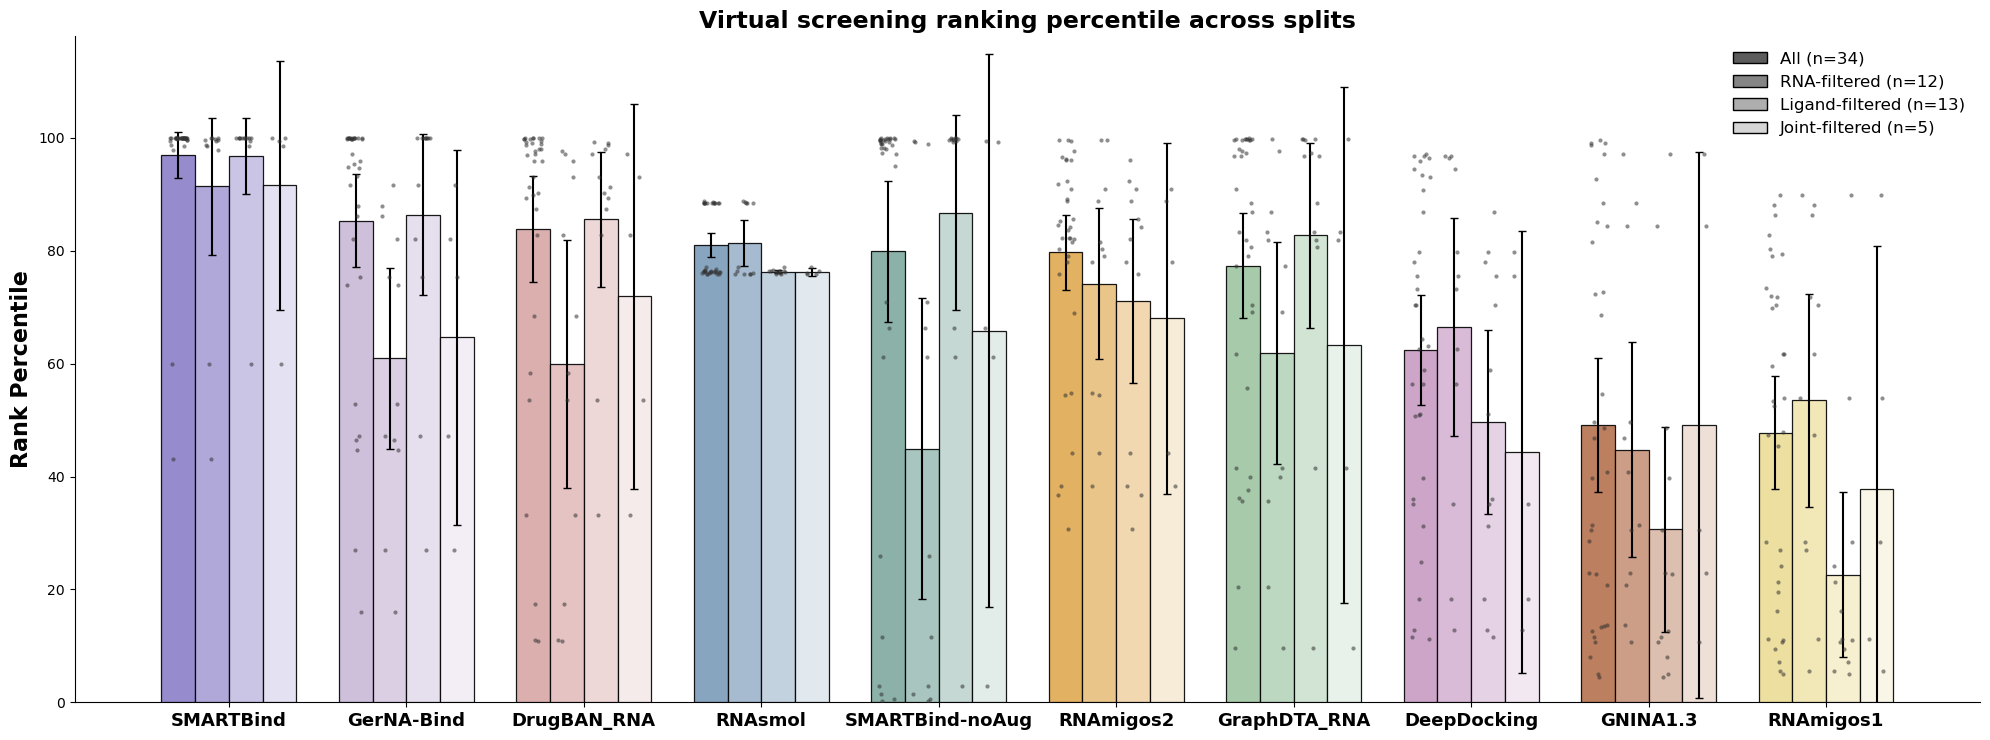

  SMARTBind All              (n=34)  96.960 ± 4.091 (95% CI)
  SMARTBind RNA-filtered     (n=12)  91.399 ± 12.060 (95% CI)
  SMARTBind Ligand-filtered  (n=13)  96.767 ± 6.698 (95% CI)
  SMARTBind Joint-filtered   (n= 5)  91.610 ± 22.021 (95% CI)


In [3]:
# ── Supplementary Fig. 9b — mean rank percentile by data-leakage filter ─────
GROUPS = ["All", "RNA-filtered", "Ligand-filtered", "Joint-filtered"]
METHOD_ORDER = ["SMARTBind", "GerNA-Bind", "DrugBAN_RNA", "RNAsmol", "SMARTBind-noAug",
                "RNAmigos2", "GraphDTA_RNA", "DeepDocking", "GNINA1.3", "RNAmigos1"]
BASE = {"SMARTBind": "#8B7FC7", "GerNA-Bind": "#C9B8D8", "DrugBAN_RNA": "#D9A7A7",
        "RNAsmol": "#7B9BB8", "SMARTBind-noAug": "#7FA9A0", "RNAmigos2": "#E0A951",
        "GraphDTA_RNA": "#9CC5A1", "DeepDocking": "#C79BC4", "GNINA1.3": "#B5714E",
        "RNAmigos1": "#EBDC96"}
n_by_group = {g: int(by_filter_summary.loc[by_filter_summary.filter_group == g,
                                           "n_targets"].iloc[0]) for g in GROUPS}


def shades(base, n):
    import matplotlib.colors as mcolors
    rgb = mcolors.to_rgb(base)
    return [tuple(1 - (1.0 - 0.75 * i / max(1, n - 1)) * (1 - c) for c in rgb) for i in range(n)]


fig, ax = plt.subplots(figsize=(20, 7.5))
width = 0.19
rng = np.random.default_rng(42)
for j, method in enumerate(METHOD_ORDER):
    grad = shades(BASE[method], len(GROUPS))
    for i, group in enumerate(GROUPS):
        vals = by_filter.loc[(by_filter.method == method)
                             & (by_filter.filter_group == group), "rank_percentile_score"].values
        mean = vals.mean()
        half = (vals.std(ddof=1) / np.sqrt(vals.size)
                * sp_stats.t.ppf(0.975, df=vals.size - 1)) if vals.size > 1 else 0.0
        pos = j + width * (i - (len(GROUPS) - 1) / 2)
        ax.bar(pos, mean, width, yerr=half, color=grad[i], edgecolor="black", linewidth=0.9,
               capsize=3, alpha=0.9, zorder=3)
        ax.scatter(np.full(vals.size, pos) + rng.uniform(-width * 0.28, width * 0.28, vals.size),
                   vals, s=9, color="#333333", alpha=0.55, zorder=6, linewidths=0)

ax.set_xticks(range(len(METHOD_ORDER)))
ax.set_xticklabels(METHOD_ORDER, fontsize=13, fontweight="bold")
ax.set_ylabel("Rank Percentile", fontsize=16, fontweight="bold")
ax.set_title("Virtual screening ranking percentile across splits", fontsize=17, fontweight="bold")
ax.set_ylim(0, 118)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(handles=[Patch(facecolor=shades("#5C5C5C", len(GROUPS))[i], edgecolor="black",
                         label=f"{g} (n={n_by_group[g]})") for i, g in enumerate(GROUPS)],
          loc="upper right", frameon=False, fontsize=12)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "SupplementaryFig9b_rank_percentile_by_filter.pdf", bbox_inches="tight", dpi=300)
plt.savefig(OUT / "SupplementaryFig9b_rank_percentile_by_filter.png", bbox_inches="tight", dpi=600)
plt.show()

for g in GROUPS:
    r = by_filter_summary[(by_filter_summary.filter_group == g)
                          & (by_filter_summary.method == "SMARTBind")].iloc[0]
    print(f"  SMARTBind {g:<16} (n={n_by_group[g]:>2})  "
          f"{r.plotted_bar_height_mean:.3f} ± {r.ci95_half_width:.3f} (95% CI)")

In [4]:
# ── Self-check: every drawn value recomputed from the per-point tables ──────
failures, checks = [], 0

for b in BASELINES:
    d = pairwise[pairwise.baseline_method == b]
    row = pairwise_summary[pairwise_summary.baseline_method == b].iloc[0]
    wins = int((d.y_baseline_inverse_rank_percentile > d.x_smartbind_inverse_rank_percentile).sum())
    losses = int((d.y_baseline_inverse_rank_percentile < d.x_smartbind_inverse_rank_percentile).sum())
    ties = int((d.y_baseline_inverse_rank_percentile == d.x_smartbind_inverse_rank_percentile).sum())
    checks += 4
    if len(d) != row.n_targets:
        failures.append(f"9a {b}: {len(d)} points vs n_targets {row.n_targets}")
    if wins != row.inset_smartbind_wins:
        failures.append(f"9a {b}: recomputed {wins} SMARTBind wins vs shipped {row.inset_smartbind_wins}")
    if losses != row.inset_baseline_wins:
        failures.append(f"9a {b}: recomputed {losses} baseline wins vs shipped {row.inset_baseline_wins}")
    if ties != row.n_ties:
        failures.append(f"9a {b}: recomputed {ties} ties vs shipped {row.n_ties}")
    # the `winner` column must agree with the coordinates it was derived from
    derived = np.where(d.y_baseline_inverse_rank_percentile > d.x_smartbind_inverse_rank_percentile,
                       "SMARTBind", b)
    checks += 1
    if not (derived == d.winner.values).all():
        failures.append(f"9a {b}: winner column disagrees with the coordinates")
print(f"Fig. 9a: 8 panels, win counts and winner column   "
      f"{'ok' if not failures else 'MISMATCH'}")

for _, row in by_filter_summary.iterrows():
    v = by_filter.loc[(by_filter.method == row.method)
                      & (by_filter.filter_group == row.filter_group), "rank_percentile_score"].values
    half = (v.std(ddof=1) / np.sqrt(v.size) * sp_stats.t.ppf(0.975, df=v.size - 1)) if v.size > 1 else 0.0
    checks += 3
    if len(v) != row.n_targets:
        failures.append(f"9b {row.filter_group}/{row.method}: n {len(v)} vs {row.n_targets}")
    if abs(v.mean() - row.plotted_bar_height_mean) > 5e-4:
        failures.append(f"9b {row.filter_group}/{row.method}: mean {v.mean():.4f} vs {row.plotted_bar_height_mean:.4f}")
    if abs(half - row.ci95_half_width) > 5e-4:
        failures.append(f"9b {row.filter_group}/{row.method}: ci95 {half:.4f} vs {row.ci95_half_width:.4f}")
print(f"Fig. 9b: {len(by_filter_summary)} bars, heights and 95% CIs           "
      f"{'ok' if not failures else 'MISMATCH'}")

print()
if failures:
    for f in failures:
        print("  " + f)
    raise AssertionError(f"{len(failures)} value(s) do not reproduce the shipped summary")
print(f"PASS: every plotted value reproduces the shipped summary tables ({checks} checks)")

Fig. 9a — 8 panels, win counts and winner column   ok
Fig. 9b — 40 bars, heights and 95% CIs           ok

PASS — every plotted value reproduces the shipped summary tables (160 checks)
